# Ділова активність і банківське кредитування в Україні

Порівняння чотирьох секторів у 2023–2025 роках для команди кредитування бізнесу. Держстат: січень–вересень; НБУ: залишки на 1 жовтня. Сукупності джерел не повністю тотожні.

In [2]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'prepare_nbu.py').is_file(), 'Запустіть з кореня проєкту або notebooks/'
sys.path.insert(0, str(ROOT / 'src'))
from prepare_nbu import load_nbu, merge_with_derzhstat
FIGURES = ROOT / 'reports' / 'figures'
PROCESSED = ROOT / 'data' / 'processed'
FIGURES.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)


## 1. Вибірка Держстату та перевірки якості

In [3]:
import pandas as pd

raw = pd.read_csv(
    ROOT / 'data' / 'raw' / 'gov_dataset.csv'
)

sectors = [
    "Переробна промисловість",
    "Будівництво",
    "Оптова та роздрібна торгівля; ремонт автотранспортних засобів і мотоциклів",
    "Транспорт, складське господарство, поштова та кур'єрська діяльність",
]

indicators = {
    "Чистий дохід від реалізації продукції (товарів, робіт, послуг)":
        "revenue",
    "Питома вага підприємств, які отримали збиток до оподаткування, у загальній кількості підприємств":
        "loss_making_share",
    "Фінансовий результат (сальдо) до оподаткування":
        "profit_before_tax",
}

periods = ["2023-Q3", "2024-Q3", "2025-Q3"]

metadata_cols = [
    c for c in raw.columns
    if not (len(c) == 7 and c[4:6] == "-Q")
]

selected = raw.loc[
    raw["Категорія розрізу"].eq("Усього")
    & raw["Територіальний розріз"].eq("Україна")
    & raw["Вид економічної діяльності"].isin(sectors)
    & raw["Показник"].isin(indicators)
]

long = (
    selected[metadata_cols + periods]
    .melt(
        id_vars=metadata_cols,
        value_vars=periods,
        var_name="period",
        value_name="value",
    )
    .drop_duplicates()  
)

key = ["Вид економічної діяльності", "Показник", "period"]

assert len(long) == 36, "Неочікувана кількість спостережень"
assert long["value"].notna().all(), "Є пропущені значення"
assert not long.duplicated(key).any(), "Є неоднозначні записи"

long["metric"] = long["Показник"].map(indicators)

analysis_df = (
    long.pivot(
        index=["Вид економічної діяльності", "period"],
        columns="metric",
        values="value",
    )
    .reset_index()
    .rename(columns={"Вид економічної діяльності": "sector"})
    .rename_axis(None, axis=1)
)

analysis_df["year"] = analysis_df["period"].str[:4].astype(int)

analysis_df["revenue_uah_mn"] = analysis_df.pop("revenue") / 1_000
analysis_df["profit_before_tax_uah_mn"] = (
    analysis_df.pop("profit_before_tax") / 1_000
)
analysis_df = analysis_df.rename(
    columns={"loss_making_share": "loss_making_share_pct"}
)

analysis_df = (
    analysis_df.sort_values(["sector", "year"])
    .reset_index(drop=True)
)

assert len(analysis_df) == 12
display(analysis_df)

,sector,period,loss_making_share_pct,year,revenue_uah_mn,profit_before_tax_uah_mn
0,Будівництво,2023-Q3,29.411765,2023,7.151740e+04,-1020.5823
1,Будівництво,2024-Q3,23.400000,2024,1.014231e+05,1741.0405
2,Будівництво,2025-Q3,18.500000,2025,1.997298e+05,5231.6915
3,Оптова та роздрібна торгівля; ремонт автотранс...,2023-Q3,15.288788,2023,2.632976e+06,86478.6634
4,Оптова та роздрібна торгівля; ремонт автотранс...,2024-Q3,16.900000,2024,3.186886e+06,84396.9620
5,Оптова та роздрібна торгівля; ремонт автотранс...,2025-Q3,16.800000,2025,3.645163e+06,113880.6785
6,Переробна промисловість,2023-Q3,18.989071,2023,1.313449e+06,87263.7705
7,Переробна промисловість,2024-Q3,20.500000,2024,1.685884e+06,91807.2373
8,Переробна промисловість,2025-Q3,19.800000,2025,2.064143e+06,128255.8130
9,"Транспорт, складське господарство, поштова та ...",2023-Q3,40.897098,2023,2.888537e+05,37259.5849


## 2. Підготовка НБУ та об’єднання

In [4]:
nbu_df = load_nbu()
combined_df = merge_with_derzhstat(analysis_df, nbu_df)
display(combined_df)


,sector,period,loss_making_share_pct,year,revenue_uah_mn,profit_before_tax_uah_mn,sector_code,loans_total_mn,loans_uah_mn,loans_fx_mn,npl_total_mn,npl_uah_mn,npl_fx_mn,npl_uah_share_pct,snapshot_date,size_scope,npl_definition,source_file
0,Будівництво,2023-Q3,29.411765,2023,7.151740e+04,-1020.5823,F,5378.712115,3795.771059,1582.941056,2848.016803,1427.968422,1420.048382,37.619983,2023-10-01,large_and_medium_NBU,Reg351_JQ,Loans_MSE_KVED_2023-10-01.xlsx
1,Будівництво,2024-Q3,23.400000,2024,1.014231e+05,1741.0405,F,6960.370651,5236.134278,1724.236373,3302.485442,1745.684152,1556.801290,33.339178,2024-10-01,large_and_medium_NBU,Reg351_JQ,Loans_MSE_KVED_2024-10-01.xlsx
2,Будівництво,2025-Q3,18.500000,2025,1.997298e+05,5231.6915,F,4767.058885,4710.249209,56.809676,1101.262366,1100.568719,0.693646,23.365403,2025-10-01,large_and_medium_NBU,Reg97_2025,Loans_MSE_KVED_2025-10-01.xlsx
3,Оптова та роздрібна торгівля; ремонт автотранс...,2023-Q3,15.288788,2023,2.632976e+06,86478.6634,G,153035.512582,113153.425671,39882.086911,63508.563796,49278.535761,14230.028035,43.550193,2023-10-01,large_and_medium_NBU,Reg351_JQ,Loans_MSE_KVED_2023-10-01.xlsx
4,Оптова та роздрібна торгівля; ремонт автотранс...,2024-Q3,16.900000,2024,3.186886e+06,84396.9620,G,186207.719660,137857.790125,48349.929535,62933.782115,49005.776897,13928.005217,35.548065,2024-10-01,large_and_medium_NBU,Reg351_JQ,Loans_MSE_KVED_2024-10-01.xlsx
5,Оптова та роздрібна торгівля; ремонт автотранс...,2025-Q3,16.800000,2025,3.645163e+06,113880.6785,G,225658.448314,163709.358161,61949.090153,62405.550827,48603.257976,13802.292850,29.688747,2025-10-01,large_and_medium_NBU,Reg97_2025,Loans_MSE_KVED_2025-10-01.xlsx
6,Переробна промисловість,2023-Q3,18.989071,2023,1.313449e+06,87263.7705,C,76421.659125,36562.506039,39859.153087,22235.590446,6280.140327,15955.450120,17.176449,2023-10-01,large_and_medium_NBU,Reg351_JQ,Loans_MSE_KVED_2023-10-01.xlsx
7,Переробна промисловість,2024-Q3,20.500000,2024,1.685884e+06,91807.2373,C,103693.509512,58162.539384,45530.970128,21829.509786,6339.590276,15489.919509,10.899782,2024-10-01,large_and_medium_NBU,Reg351_JQ,Loans_MSE_KVED_2024-10-01.xlsx
8,Переробна промисловість,2025-Q3,19.800000,2025,2.064143e+06,128255.8130,C,130977.192842,83313.159231,47664.033611,16470.430069,4676.531756,11793.898313,5.613197,2025-10-01,large_and_medium_NBU,Reg97_2025,Loans_MSE_KVED_2025-10-01.xlsx
9,"Транспорт, складське господарство, поштова та ...",2023-Q3,40.897098,2023,2.888537e+05,37259.5849,H,15343.963242,10008.277786,5335.685457,8099.330480,4456.935669,3642.394811,44.532494,2023-10-01,large_and_medium_NBU,Reg351_JQ,Loans_MSE_KVED_2023-10-01.xlsx


## 3. Зміни показників

In [5]:
import numpy as np
import pandas as pd

metrics_df = (
    combined_df.copy()
    .sort_values(["sector", "year"])
    .reset_index(drop=True)
)

assert not metrics_df.duplicated(["sector", "year"]).any()

grouped = metrics_df.groupby("sector", sort=False)
previous_year = grouped["year"].shift(1)
consecutive_year = metrics_df["year"].sub(previous_year).eq(1)

for source, target in {
    "revenue_uah_mn": "revenue_growth_pct",
    "loans_uah_mn": "loans_growth_pct",
}.items():
    previous = grouped[source].shift(1)

    metrics_df[target] = (
        metrics_df[source]
        .div(previous.where(previous > 0))
        .sub(1)
        .mul(100)
        .where(consecutive_year)
    )

metrics_df["loss_share_change_pp"] = (
    grouped["loss_making_share_pct"]
    .diff()
    .where(consecutive_year)
)


metrics_df["profit_change_uah_mn"] = (
    grouped["profit_before_tax_uah_mn"]
    .diff()
    .where(consecutive_year)
)

metrics_df["credit_revenue_growth_difference_pp"] = (
    metrics_df["loans_growth_pct"]
    - metrics_df["revenue_growth_pct"]
)

calculated_cols = [
    "revenue_growth_pct",
    "loans_growth_pct",
    "loss_share_change_pp",
    "profit_change_uah_mn",
    "credit_revenue_growth_difference_pp",
]
assert not np.isinf(
    metrics_df[calculated_cols].to_numpy(dtype=float)
).any()

comparison = metrics_df.loc[
    consecutive_year,
    ["sector", "year"] + calculated_cols
]

display(
    comparison.rename(columns={
        "sector": "Сектор",
        "year": "Рік",
        "revenue_growth_pct": "Зміна доходу, %",
        "loans_growth_pct": "Зміна кредитів, %",
        "loss_share_change_pp": "Зміна частки збиткових, в. п.",
        "profit_change_uah_mn": "Зміна фінрезультату, млн грн",
        "credit_revenue_growth_difference_pp":
            "Темп кредитів мінус темп доходу, в. п.",
    }).round(2)
)

,Сектор,Рік,"Зміна доходу, %","Зміна кредитів, %","Зміна частки збиткових, в. п.","Зміна фінрезультату, млн грн","Темп кредитів мінус темп доходу, в. п."
1,Будівництво,2024,41.82,37.95,-6.01,2761.62,-3.87
2,Будівництво,2025,96.93,-10.04,-4.90,3490.65,-106.97
4,Оптова та роздрібна торгівля; ремонт автотранс...,2024,21.04,21.83,1.61,-2081.70,0.80
5,Оптова та роздрібна торгівля; ремонт автотранс...,2025,14.38,18.75,-0.10,29483.72,4.37
7,Переробна промисловість,2024,28.36,59.08,1.51,4543.47,30.72
8,Переробна промисловість,2025,22.44,43.24,-0.70,36448.58,20.81
10,"Транспорт, складське господарство, поштова та ...",2024,20.21,29.21,-1.00,1467.28,9.00
11,"Транспорт, складське господарство, поштова та ...",2025,-3.88,-25.60,1.80,-25453.72,-21.72


## 4. Абсолютні значення

In [6]:
level_check = (
    metrics_df[
        [
            "sector",
            "year",
            "revenue_uah_mn",
            "profit_before_tax_uah_mn",
            "loss_making_share_pct",
            "loans_uah_mn",
        ]
    ]
    .sort_values(["sector", "year"])
)

display(
    level_check.rename(columns={
        "sector": "Сектор",
        "year": "Рік",
        "revenue_uah_mn": "Дохід, млн грн",
        "profit_before_tax_uah_mn": "Фінрезультат, млн грн",
        "loss_making_share_pct": "Збиткові підприємства, %",
        "loans_uah_mn": "Гривневі кредити, млн грн",
    }).round(2)
)

,Сектор,Рік,"Дохід, млн грн","Фінрезультат, млн грн","Збиткові підприємства, %","Гривневі кредити, млн грн"
0,Будівництво,2023,71517.40,-1020.58,29.41,3795.77
1,Будівництво,2024,101423.12,1741.04,23.40,5236.13
2,Будівництво,2025,199729.78,5231.69,18.50,4710.25
3,Оптова та роздрібна торгівля; ремонт автотранс...,2023,2632975.88,86478.66,15.29,113153.43
4,Оптова та роздрібна торгівля; ремонт автотранс...,2024,3186886.15,84396.96,16.90,137857.79
5,Оптова та роздрібна торгівля; ремонт автотранс...,2025,3645162.66,113880.68,16.80,163709.36
6,Переробна промисловість,2023,1313448.84,87263.77,18.99,36562.51
7,Переробна промисловість,2024,1685883.98,91807.24,20.50,58162.54
8,Переробна промисловість,2025,2064143.19,128255.81,19.80,83313.16
9,"Транспорт, складське господарство, поштова та ...",2023,288853.74,37259.58,40.90,10008.28


## 5. Дохід і кредитні залишки

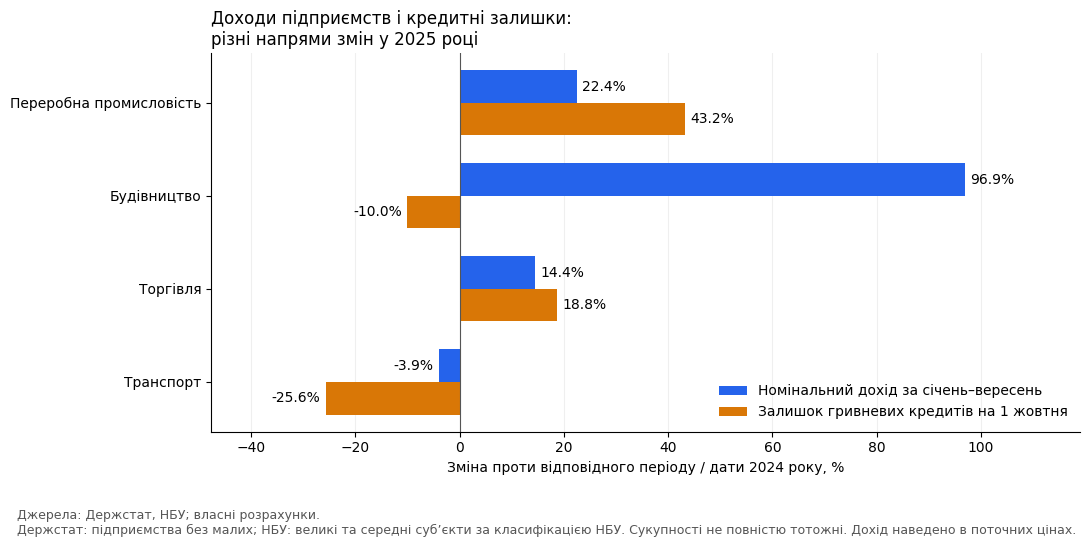

In [7]:
import matplotlib.pyplot as plt
import numpy as np

sector_labels = {
    "C": "Переробна промисловість",
    "F": "Будівництво",
    "G": "Торгівля",
    "H": "Транспорт",
}

plot_df = (
    metrics_df.loc[metrics_df["year"].eq(2025)]
    .set_index("sector_code")
    .loc[["C", "F", "G", "H"]]
)

assert plot_df[
    ["revenue_growth_pct", "loans_growth_pct"]
].notna().all().all()

y = np.arange(len(plot_df))
height = 0.35

fig, ax = plt.subplots(figsize=(11, 5.5))

revenue_bars = ax.barh(
    y - height / 2,
    plot_df["revenue_growth_pct"],
    height,
    label="Номінальний дохід за січень–вересень",
    color="#2563EB",
)

loan_bars = ax.barh(
    y + height / 2,
    plot_df["loans_growth_pct"],
    height,
    label="Залишок гривневих кредитів на 1 жовтня",
    color="#D97706",
)

ax.bar_label(revenue_bars, fmt="%.1f%%", padding=4)
ax.bar_label(loan_bars, fmt="%.1f%%", padding=4)

ax.set_yticks(y)
ax.set_yticklabels([sector_labels[c] for c in plot_df.index])
ax.invert_yaxis()
ax.axvline(0, color="#555555", linewidth=0.8)

ax.set_xlabel("Зміна проти відповідного періоду / дати 2024 року, %")
ax.set_title(
    "Доходи підприємств і кредитні залишки:\n"
    "різні напрями змін у 2025 році",
    loc="left",
)

ax.legend(loc="lower right", frameon=False)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
ax.margins(x=0.18)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

fig.text(
    0.02, 0.02,
    "Джерела: Держстат, НБУ; власні розрахунки.\n"
    "Держстат: підприємства без малих; НБУ: великі та середні суб’єкти за класифікацією НБУ. Сукупності не повністю тотожні. Дохід наведено в поточних цінах.",
    fontsize=9,
    color="#555555",
)

fig.tight_layout(rect=[0, 0.10, 1, 1])
fig.savefig(FIGURES / 'revenue_and_lending.png', dpi=160, bbox_inches='tight')
plt.show()

## 6. Частка збиткових підприємств

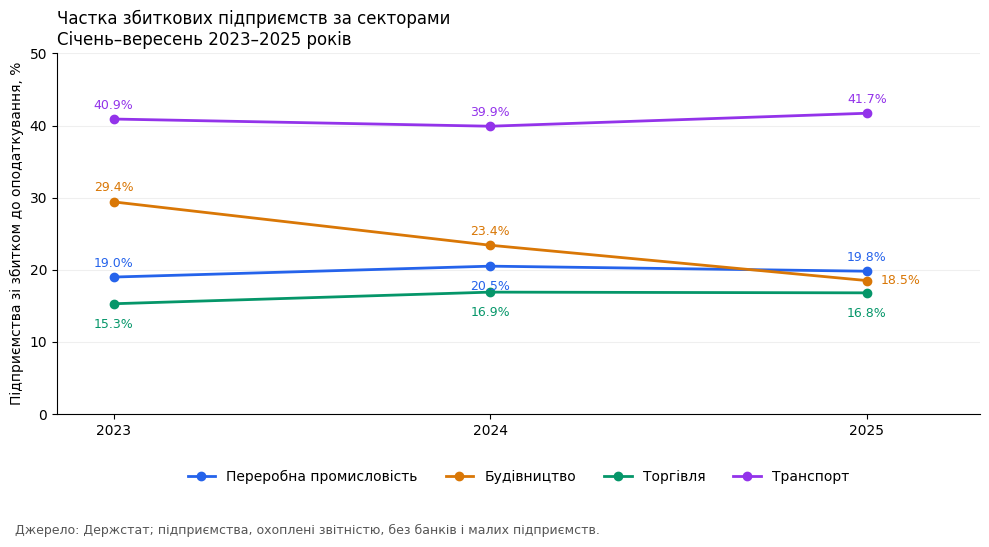

In [8]:
import matplotlib.pyplot as plt

sector_labels = {
    "C": "Переробна промисловість",
    "F": "Будівництво",
    "G": "Торгівля",
    "H": "Транспорт",
}

colors = {
    "C": "#2563EB",
    "F": "#D97706",
    "G": "#059669",
    "H": "#9333EA",
}

default_label = ((0, 10), "center")
label_pos = {
    ("C", 2024): ((0, -15), "center"),  
    ("F", 2025): ((10, 0), "left"),     
    ("G", 2023): ((0, -15), "center"),
    ("G", 2024): ((0, -15), "center"),
    ("G", 2025): ((0, -15), "center"),
}

fig, ax = plt.subplots(figsize=(10, 5.5))

for code, label in sector_labels.items():
    sector_data = (
        metrics_df.loc[metrics_df["sector_code"].eq(code)]
        .sort_values("year")
    )

    ax.plot(
        sector_data["year"],
        sector_data["loss_making_share_pct"],
        marker="o",
        linewidth=2,
        color=colors[code],
        label=label,
    )

    for year, share in zip(
        sector_data["year"],
        sector_data["loss_making_share_pct"],
    ):
        offset, ha = label_pos.get((code, int(year)), default_label)
        ax.annotate(
            f"{share:.1f}%",
            (year, share),
            xytext=offset,
            textcoords="offset points",
            ha=ha,
            va="center",
            fontsize=9,
            color=colors[code],
        )

ax.set_title(
    "Частка збиткових підприємств за секторами\n"
    "Січень–вересень 2023–2025 років",
    loc="left",
)
ax.set_ylabel("Підприємства зі збитком до оподаткування, %")
ax.set_xticks([2023, 2024, 2025])
ax.set_xlim(2022.85, 2025.3)   
ax.set_ylim(0, 50)
ax.grid(axis="y", alpha=0.2)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4,
    frameon=False,
)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

fig.text(
    0.02, 0.02,
    "Джерело: Держстат; підприємства, охоплені звітністю, "
    "без банків і малих підприємств.",
    fontsize=9,
    color="#555555",
)

fig.tight_layout(rect=[0, 0.06, 1, 1])
fig.savefig(FIGURES / 'loss_making_enterprises.png', dpi=160, bbox_inches='tight')
plt.show()


## 7. Фінансовий результат

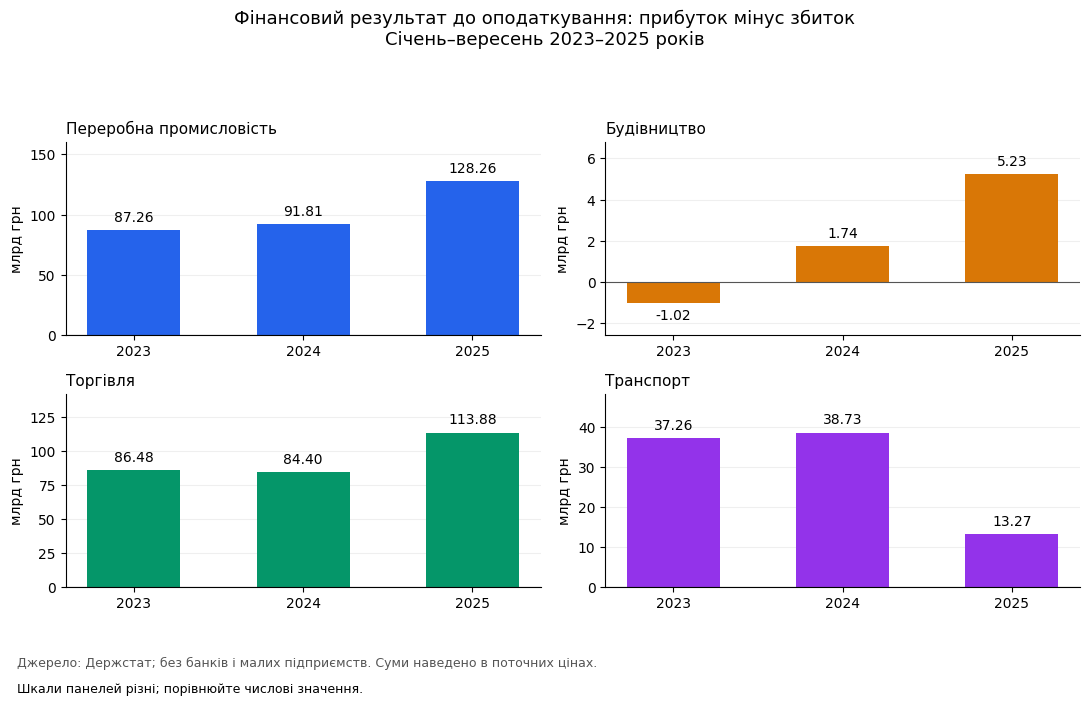

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
order = ["C", "F", "G", "H"]

for ax, code in zip(axes.flat, order):
    data = (
        metrics_df.loc[metrics_df["sector_code"].eq(code)]
        .sort_values("year")
    )

    # млн грн → млрд грн
    profit_bn = data["profit_before_tax_uah_mn"] / 1_000

    bars = ax.bar(
        data["year"].astype(str),
        profit_bn,
        color=colors[code],
        width=0.55,
    )

    ax.bar_label(bars, fmt="%.2f", padding=4)
    ax.axhline(0, color="#555555", linewidth=0.8)
    ax.set_title(sector_labels[code], loc="left", fontsize=11)
    ax.set_ylabel("млрд грн")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.margins(y=0.25)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

fig.suptitle(
    "Фінансовий результат до оподаткування: прибуток мінус збиток\n"
    "Січень–вересень 2023–2025 років",
    fontsize=13,
)

fig.text(
    0.02, 0.02,
    "Джерело: Держстат; без банків і малих підприємств. "
    "Суми наведено в поточних цінах.\n",
    fontsize=9,
    color="#555555",
)

fig.text(0.02, 0.005, "Шкали панелей різні; порівнюйте числові значення.", fontsize=9)
fig.tight_layout(rect=[0, 0.10, 1, 0.92])
fig.savefig(FIGURES / 'financial_results.png', dpi=160, bbox_inches='tight')
plt.show()

## 8. Джерела приросту доходу будівництва

In [10]:
names = [
    "Будівництво",
    "Будівництво будівель",
    "Будівництво споруд",
    "Спеціалізовані будівельні роботи",
]
periods = ["2024-Q3", "2025-Q3"]

selected = raw.loc[
    raw["Категорія розрізу"].eq("Усього")
    & raw["Територіальний розріз"].eq("Україна")
    & raw["Показник"].eq(
        "Чистий дохід від реалізації продукції (товарів, робіт, послуг)"
    )
    & raw["Вид економічної діяльності"].isin(names)
].drop_duplicates()

assert len(selected) == 4
assert not selected["Вид економічної діяльності"].duplicated().any()
assert selected["Одиниця виміру"].eq("Гривня").all()
assert selected["Масштабування"].eq("Тисячі").all()

values = (
    selected.set_index("Вид економічної діяльності")[periods]
    .apply(pd.to_numeric, errors="raise")
)

assert values.notna().all().all()

total = values.loc["Будівництво"]
construction_detail = values.drop(index="Будівництво").copy()

assert np.allclose(
    construction_detail.sum().to_numpy(),
    total.to_numpy(),
    atol=0.1,  # тис. грн
    rtol=0,
)

construction_detail = construction_detail / 1_000

construction_detail["increase_uah_mn"] = (
    construction_detail["2025-Q3"]
    - construction_detail["2024-Q3"]
)

total_increase_mn = (total["2025-Q3"] - total["2024-Q3"]) / 1_000

construction_detail["contribution_pct"] = (
    construction_detail["increase_uah_mn"]
    / total_increase_mn
    * 100
)

display(construction_detail.round(2))

,2024-Q3,2025-Q3,increase_uah_mn,contribution_pct
Вид економічної діяльності,,,,
Спеціалізовані будівельні роботи,15075.11,29165.14,14090.03,14.33
Будівництво будівель,44094.42,55385.68,11291.25,11.49
Будівництво споруд,42253.59,115178.97,72925.38,74.18


## 9. Кредитування розділів 41–43

In [11]:
from pathlib import Path

base = ROOT / 'data' / 'raw'
sizes = [
    "Суб'єкт великого підприємництва",
    "Суб'єкт середнього підприємництва",
]
division_names = {
    41: "Будівництво будівель",
    42: "Будівництво споруд",
    43: "Спеціалізовані будівельні роботи",
}

yearly = []

for year in [2024, 2025]:
    path = base / f"Loans_MSE_KVED_{year}-10-01.xlsx"

    data = pd.read_excel(
        path,
        sheet_name=f"вересень {year}",
        header=None,
    ).iloc[5:, :6].copy()

    data.columns = [
        "size", "division", "division_name",
        "loans_total", "loans_uah", "loans_fx",
    ]

    data["division"] = pd.to_numeric(
        data["division"], errors="raise"
    ).astype(int)

    data["loans_uah"] = pd.to_numeric(
        data["loans_uah"], errors="raise"
    )

    selected = data.loc[
        data["size"].isin(sizes)
        & data["division"].isin(division_names)
    ]

    assert not selected.duplicated(["size", "division"]).any()
    assert selected["loans_uah"].notna().all()

    amounts = (
        selected.groupby("division")["loans_uah"]
        .sum(min_count=1)
        .div(1_000)
        .rename(f"loans_{year}_mn")
    )
    yearly.append(amounts)

construction_loans = pd.concat(yearly, axis=1)

assert set(construction_loans.index) == {41, 42, 43}
assert construction_loans.notna().all().all()

construction_loans["change_mn"] = (
    construction_loans["loans_2025_mn"]
    - construction_loans["loans_2024_mn"]
)
construction_loans["growth_pct"] = (
    construction_loans["loans_2025_mn"]
    .div(construction_loans["loans_2024_mn"].replace(0, np.nan))
    .sub(1)
    .mul(100)
)
construction_loans["division_name"] = (
    construction_loans.index.map(division_names)
)

display(construction_loans.round(2))

,loans_2024_mn,loans_2025_mn,change_mn,growth_pct,division_name
division,,,,,
41,1444.13,2521.38,1077.26,74.60,Будівництво будівель
42,3357.55,1632.14,-1725.41,-51.39,Будівництво споруд
43,434.46,556.73,122.27,28.14,Спеціалізовані будівельні роботи


## 10. Деталізація розходження

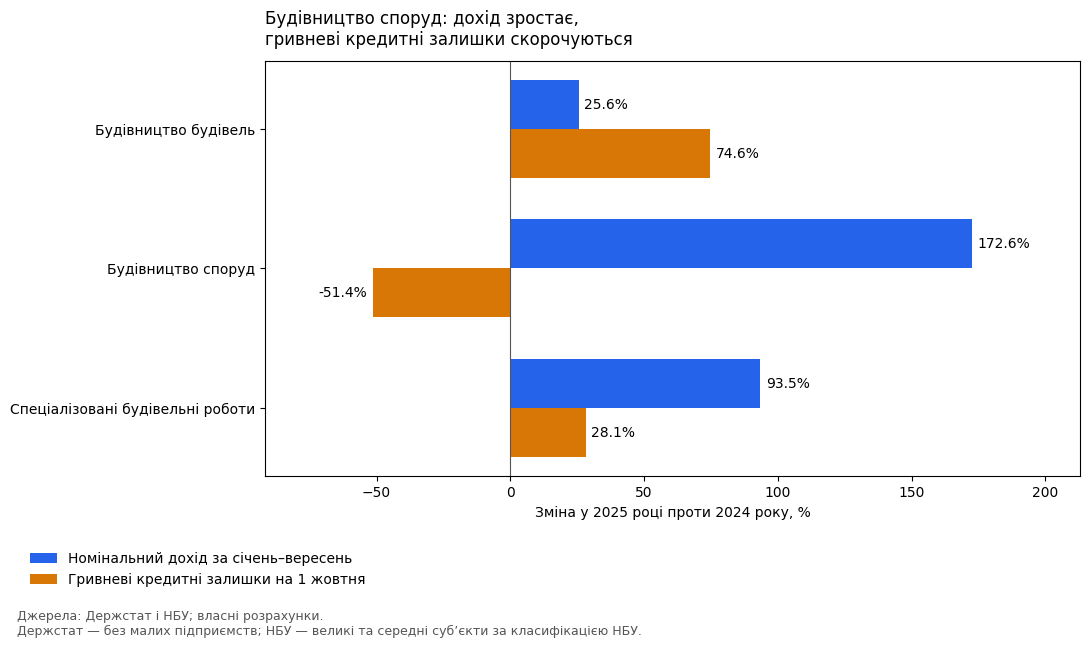

In [12]:
construction_comparison = (construction_detail.rename_axis('division_name').reset_index().merge(construction_loans.reset_index(), on='division_name', how='outer', validate='one_to_one', indicator=True))
assert construction_comparison['_merge'].eq('both').all()
construction_comparison = construction_comparison.drop(columns='_merge').sort_values('division')
construction_comparison['revenue_growth_pct'] = (construction_comparison['2025-Q3'] / construction_comparison['2024-Q3'] - 1) * 100
y = np.arange(len(construction_comparison))
height = 0.35

fig, ax = plt.subplots(figsize=(11, 6.5))

revenue_bars = ax.barh(
    y - height / 2,
    construction_comparison["revenue_growth_pct"],
    height,
    color="#2563EB",
    label="Номінальний дохід за січень–вересень",
)

loan_bars = ax.barh(
    y + height / 2,
    construction_comparison["growth_pct"],
    height,
    color="#D97706",
    label="Гривневі кредитні залишки на 1 жовтня",
)

ax.bar_label(revenue_bars, fmt="%.1f%%", padding=4)
ax.bar_label(loan_bars, fmt="%.1f%%", padding=4)

ax.set_yticks(y)
ax.set_yticklabels(construction_comparison["division_name"])
ax.invert_yaxis()
ax.axvline(0, color="#555555", linewidth=0.8)
ax.margins(x=0.18)
ax.set_xlabel("Зміна у 2025 році проти 2024 року, %")
ax.set_title(
    "Будівництво споруд: дохід зростає,\n"
    "гривневі кредитні залишки скорочуються",
    loc="left",
    pad=12,
)

fig.legend(
    handles=[revenue_bars, loan_bars],
    loc="lower left",
    bbox_to_anchor=(0.02, 0.07),
    frameon=False,
    ncol=1,
)

fig.text(
    0.02, 0.01,
    "Джерела: Держстат і НБУ; власні розрахунки.\n"
    "Держстат — без малих підприємств; НБУ — великі та середні "
    "суб’єкти за класифікацією НБУ.",
    fontsize=9,
    color="#555555",
    va="bottom",
)

fig.tight_layout(rect=[0, 0.17, 1, 1])
fig.savefig(FIGURES / 'construction_breakdown.png', dpi=160, bbox_inches='tight')
plt.show()


## 11. Перевірка валютної складової

In [13]:
currency_rows = []

for year in [2024, 2025]:
    path = base / f"Loans_MSE_KVED_{year}-10-01.xlsx"

    data = pd.read_excel(
        path,
        sheet_name=f"вересень {year}",
        header=None,
    ).iloc[5:, :6].copy()

    data.columns = [
        "size", "division", "division_name",
        "loans_total", "loans_uah", "loans_fx",
    ]

    data["division"] = pd.to_numeric(
        data["division"], errors="raise"
    ).astype(int)

    selected = data.loc[
        data["size"].isin(sizes)
        & data["division"].eq(42)
    ].copy()

    money_cols = ["loans_total", "loans_uah", "loans_fx"]
    selected[money_cols] = selected[money_cols].apply(
        pd.to_numeric, errors="raise"
    )

    assert len(selected) == 2
    assert set(selected["size"]) == set(sizes)
    assert selected[money_cols].notna().all().all()
    assert np.allclose(
        selected["loans_total"],
        selected["loans_uah"] + selected["loans_fx"],
        atol=0.01,
        rtol=0,
    )

    # тис. грн → млн грн
    currency_rows.append(
        selected[money_cols].sum().div(1_000).rename(year)
    )

currency_check = pd.concat(currency_rows, axis=1)
currency_check["change_mn"] = (
    currency_check[2025] - currency_check[2024]
)
currency_check["growth_pct"] = (
    currency_check[2025]
    .div(currency_check[2024].replace(0, np.nan))
    .sub(1)
    .mul(100)
)

display(currency_check.round(2))

,2024,2025,change_mn,growth_pct
loans_total,3448.84,1653.51,-1795.33,-52.06
loans_uah,3357.55,1632.14,-1725.41,-51.39
loans_fx,91.30,21.38,-69.92,-76.59


## 12. Експорт результатів

In [14]:
metrics_df.to_csv(PROCESSED / 'sector_metrics.csv', index=False, encoding='utf-8-sig')
construction_detail.to_csv(PROCESSED / 'construction_revenue.csv', index=True, encoding='utf-8-sig')
construction_loans.to_csv(PROCESSED / 'construction_loans.csv', index=True, encoding='utf-8-sig')
currency_check.to_csv(PROCESSED / 'construction_currency_check.csv', index=True, encoding='utf-8-sig')


## Висновки та обмеження

Будівництво споруд сформувало 74,18% приросту доходу будівництва, але його загальні кредитні залишки скоротилися на 52,06%. Це напрям подальшого дослідження фінансування, а не доказ незадоволеного попиту. У транспорті скорочення кредитів супроводжується погіршенням фінансових показників.

Дохід номінальний; охоплення джерел відрізняється; склад звітуючих підприємств може змінюватися. Залишки не розкривають видачі, погашення й списання. Визначення NPL у 2025 році змінилося; його динаміку не інтерпретуємо як однорідний ряд.